# 03 — TsHARP Downscaling

## Explainable ML for LST Downscaling in Lucknow

This notebook implements a controlled TsHARP thermal downscaling experiment for the Lucknow study area.

The notebook:
- prepares a controlled 90 m coarse-resolution LST,
- derives fractional vegetation cover (FVC) from NDVI,
- establishes the coarse LST–FVC relationship,
- generates an initial 30 m LST estimate,
- applies the TsHARP residual correction,
- evaluates the result using a controlled pseudo-validation experiment,
- and saves the final TsHARP LST and diagnostic outputs.

### 1. Load the prepared raster datasets

The required LST and predictor rasters were generated in the previous notebooks and saved in `data/processed/lucknow/`.

In this notebook, we load these existing GeoTIFF files rather than recalculating them.

The main datasets are:

- LST
- NDVI
- NDBI
- MNDWI
- Green
- SWIR1
- SWIR2

In [1]:
from pathlib import Path
import rasterio
import numpy as np

# Project paths
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "lucknow"/ "fine"/ "predictors"

print("Processed data folder:", PROCESSED_DIR)

Processed data folder: d:\Projects\GeoAI-LST-Downscaling\data\processed\lucknow\fine\predictors


In [2]:
# Paths to the prepared datasets

raster_paths = {
    "LST": PROCESSED_DIR / "lst_clean_lucknow.tif",
    "NDVI": PROCESSED_DIR / "ndvi_lucknow.tif",
    "NDBI": PROCESSED_DIR / "ndbi_lucknow.tif",
    "MNDWI": PROCESSED_DIR / "mndwi_lucknow.tif",
    "Green": PROCESSED_DIR / "green_lucknow_reflectance.tif",
    "SWIR1": PROCESSED_DIR / "swir1_lucknow_reflectance.tif",
    "SWIR2": PROCESSED_DIR / "swir2_lucknow_reflectance.tif",
}

for name, path in raster_paths.items():
    print(name, "→", path.name)

LST → lst_clean_lucknow.tif
NDVI → ndvi_lucknow.tif
NDBI → ndbi_lucknow.tif
MNDWI → mndwi_lucknow.tif
Green → green_lucknow_reflectance.tif
SWIR1 → swir1_lucknow_reflectance.tif
SWIR2 → swir2_lucknow_reflectance.tif


### 2. Inspect spatial properties

Before modifying the rasters, we inspect their spatial metadata.

The most important properties are:

- Shape: number of rows and columns
- CRS: coordinate reference system
- Resolution: physical dimensions of each pixel
- Transform: relationship between raster pixels and geographic coordinates
- Extent: geographic area covered by the raster

This allows us to determine whether the datasets are already spatially compatible or require resampling/alignment.

In [3]:
for name, path in raster_paths.items():

    with rasterio.open(path) as src:
        print(
            f"{name:6} | "
            f"shape={src.height}x{src.width} | "
            f"CRS={src.crs} | "
            f"res={src.res} | "
            f"bounds={src.bounds} | "
            f"nodata={src.nodata}"
        )

LST    | shape=703x762 | CRS=EPSG:32644 | res=(30.0, 30.0) | bounds=BoundingBox(left=483225.0, bottom=2958075.0, right=506085.0, top=2979165.0) | nodata=-9999.0
NDVI   | shape=703x762 | CRS=EPSG:32644 | res=(30.0, 30.0) | bounds=BoundingBox(left=483225.0, bottom=2958075.0, right=506085.0, top=2979165.0) | nodata=-9999.0
NDBI   | shape=703x762 | CRS=EPSG:32644 | res=(30.0, 30.0) | bounds=BoundingBox(left=483225.0, bottom=2958075.0, right=506085.0, top=2979165.0) | nodata=0.0
MNDWI  | shape=703x762 | CRS=EPSG:32644 | res=(30.0, 30.0) | bounds=BoundingBox(left=483225.0, bottom=2958075.0, right=506085.0, top=2979165.0) | nodata=0.0
Green  | shape=703x762 | CRS=EPSG:32644 | res=(30.0, 30.0) | bounds=BoundingBox(left=483225.0, bottom=2958075.0, right=506085.0, top=2979165.0) | nodata=0.0
SWIR1  | shape=703x762 | CRS=EPSG:32644 | res=(30.0, 30.0) | bounds=BoundingBox(left=483225.0, bottom=2958075.0, right=506085.0, top=2979165.0) | nodata=0.0
SWIR2  | shape=703x762 | CRS=EPSG:32644 | res=(30.

### 3. Create a controlled coarse-resolution LST

The Landsat-8 thermal bands have a native spatial resolution of approximately 100 m, while the delivered Level-2 surface-temperature product is provided on a 30 m grid.

For our controlled thermal-sharpening experiment, we aggregate the 30 m LST to a 90 m grid using 3 × 3 pixel blocks.

A 90 m grid is used because it is an exact multiple of the 30 m Landsat grid, allowing consistent aggregation without introducing an additional resampling step.

This 90 m LST should be interpreted as a controlled coarse-resolution representation for the experiment, not as the native TIRS resolution.

In [4]:
# Load the LST raster

with rasterio.open(raster_paths["LST"]) as src:
    lst = src.read(1).astype("float32")
    lst_profile = src.profile
    lst_transform = src.transform

print("LST shape:", lst.shape)
print("LST resolution:", src.res)

LST shape: (703, 762)
LST resolution: (30.0, 30.0)


### 4. Aggregate LST to a 90 m grid

The 30 m LST raster is aggregated into 90 m pixels using non-overlapping 3 × 3 pixel blocks.

Because the original raster has 703 rows, one row cannot form a complete 3 × 3 block. We therefore use the largest complete portion of the raster:

702 × 762 pixels.

Each 90 m pixel represents the mean LST of its corresponding 3 × 3 block of 30 m pixels.

The resulting coarse raster has:

234 rows × 254 columns.

In [5]:
# Define the aggregation factor

AGG_FACTOR = 3

# Remove the incomplete final row
rows = (lst.shape[0] // AGG_FACTOR) * AGG_FACTOR
cols = (lst.shape[1] // AGG_FACTOR) * AGG_FACTOR

lst_trimmed = lst[:rows, :cols]

print("Original LST shape :", lst.shape)
print("Trimmed LST shape  :", lst_trimmed.shape)

Original LST shape : (703, 762)
Trimmed LST shape  : (702, 762)


In [6]:
# Reshape into 3 × 3 blocks and calculate the mean

coarse_lst = lst_trimmed.reshape(
    rows // AGG_FACTOR,
    AGG_FACTOR,
    cols // AGG_FACTOR,
    AGG_FACTOR
).mean(axis=(1, 3))

print("Coarse LST shape:", coarse_lst.shape)

Coarse LST shape: (234, 254)


In [7]:
# Check the amount of NoData in the LST

nodata_value = -9999

nodata_count = np.sum(lst == nodata_value)
valid_count = np.sum(lst != nodata_value)

print("Total pixels :", lst.size)
print("Valid pixels :", valid_count)
print("NoData pixels:", nodata_count)
print("NoData percentage:", (nodata_count / lst.size) * 100)

Total pixels : 535686
Valid pixels : 535686
NoData pixels: 0
NoData percentage: 0.0


#### 4.1 NoData-aware LST aggregation

The LST raster contains a substantial amount of NoData pixels.

Therefore, the coarse LST is calculated using only valid 30 m LST observations within each 3 × 3 block.

If a block contains no valid observations, the resulting coarse pixel is assigned NoData.

In [8]:
# Replace NoData with NaN for safe aggregation

lst_for_aggregation = lst_trimmed.copy()
lst_for_aggregation[lst_for_aggregation == nodata_value] = np.nan

# Reshape into 3 × 3 blocks

lst_blocks = lst_for_aggregation.reshape(
    rows // AGG_FACTOR,
    AGG_FACTOR,
    cols // AGG_FACTOR,
    AGG_FACTOR
)

# Calculate the mean while ignoring NaN values

coarse_lst = np.nanmean(lst_blocks, axis=(1, 3))

# Identify blocks where every pixel was NoData

all_nodata = np.all(
    np.isnan(lst_blocks),
    axis=(1, 3)
)

coarse_lst[all_nodata] = np.nan

print("Coarse LST shape:", coarse_lst.shape)
print("Coarse LST NoData pixels:", np.sum(np.isnan(coarse_lst)))
print(
    "Coarse LST valid pixels:",
    np.sum(~np.isnan(coarse_lst))
)

Coarse LST shape: (234, 254)
Coarse LST NoData pixels: 24053
Coarse LST valid pixels: 35383


C:\Users\ANSHIKA\AppData\Local\Temp\ipykernel_22308\3560730019.py:17: RuntimeWarning: Mean of empty slice
  coarse_lst = np.nanmean(lst_blocks, axis=(1, 3))


In [9]:
# Check the valid coarse LST values

print("Minimum coarse LST:", np.nanmin(coarse_lst))
print("Maximum coarse LST:", np.nanmax(coarse_lst))
print("Mean coarse LST:", np.nanmean(coarse_lst))
print("Median coarse LST:", np.nanmedian(coarse_lst))

Minimum coarse LST: 32.28329
Maximum coarse LST: 44.784115
Mean coarse LST: 39.171635
Median coarse LST: 39.309586


### 5. Create the spatial metadata for the coarse LST

The aggregated LST is now a 234 × 254 array.

Because each coarse pixel represents a 3 × 3 block of 30 m pixels, the new pixel size is 90 m.

We preserve the original CRS and update the affine transform to represent the new 90 m grid.

In [10]:
from rasterio.transform import Affine

# Create the transform for the 90 m coarse grid

coarse_transform = Affine(
    lst_transform.a * AGG_FACTOR,
    lst_transform.b,
    lst_transform.c,
    lst_transform.d,
    lst_transform.e * AGG_FACTOR,
    lst_transform.f
)

print("Original resolution :", lst_transform.a, abs(lst_transform.e))
print("Coarse resolution   :", coarse_transform.a, abs(coarse_transform.e))
print("Coarse transform:")
print(coarse_transform)

Original resolution : 30.0 30.0
Coarse resolution   : 90.0 90.0
Coarse transform:
| 90.00, 0.00, 483225.00|
| 0.00,-90.00, 2979165.00|
| 0.00, 0.00, 1.00|


### 6. Save the 90 m coarse LST

The 90 m coarse LST is saved as a GeoTIFF while preserving its CRS, spatial transform and NoData information.

This raster will serve as the coarse-resolution LST input for the TsHARP experiment.

In [11]:
# Prepare output path
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "lucknow" 
COARSE_DIR = PROCESSED_DIR / "coarse"
COARSE_DIR.mkdir(parents=True, exist_ok=True)

coarse_lst_path = COARSE_DIR / "tsharp_lst_90m_lucknow.tif"


# Create GeoTIFF profile

coarse_lst_profile = lst_profile.copy()

coarse_lst_profile.update({
    "driver": "GTiff",
    "height": coarse_lst.shape[0],
    "width": coarse_lst.shape[1],
    "count": 1,
    "dtype": "float32",
    "crs": "EPSG:32644",
    "transform": coarse_transform,
    "nodata": -9999.0
})


# Convert NaN back to the GeoTIFF NoData value

coarse_lst_to_save = np.where(
    np.isnan(coarse_lst),
    -9999.0,
    coarse_lst
).astype("float32")


# Save

with rasterio.open(coarse_lst_path, "w", **coarse_lst_profile) as dst:
    dst.write(coarse_lst_to_save, 1)

print("Saved:", coarse_lst_path)

Saved: d:\Projects\GeoAI-LST-Downscaling\data\processed\lucknow\coarse\tsharp_lst_90m_lucknow.tif


In [12]:
with rasterio.open(coarse_lst_path) as src:
    print("Shape      :", (src.height, src.width))
    print("CRS        :", src.crs)
    print("Resolution :", src.res)
    print("NoData     :", src.nodata)
    print("Bounds     :", src.bounds)

Shape      : (234, 254)
CRS        : EPSG:32644
Resolution : (90.0, 90.0)
NoData     : -9999.0
Bounds     : BoundingBox(left=483225.0, bottom=2958105.0, right=506085.0, top=2979165.0)


### 7. Visualize the 90 m coarse LST

The coarse LST is plotted to visually inspect the spatial pattern after aggregation.

Aggregation should smooth small-scale temperature variations while preserving the broader spatial pattern of the original LST.

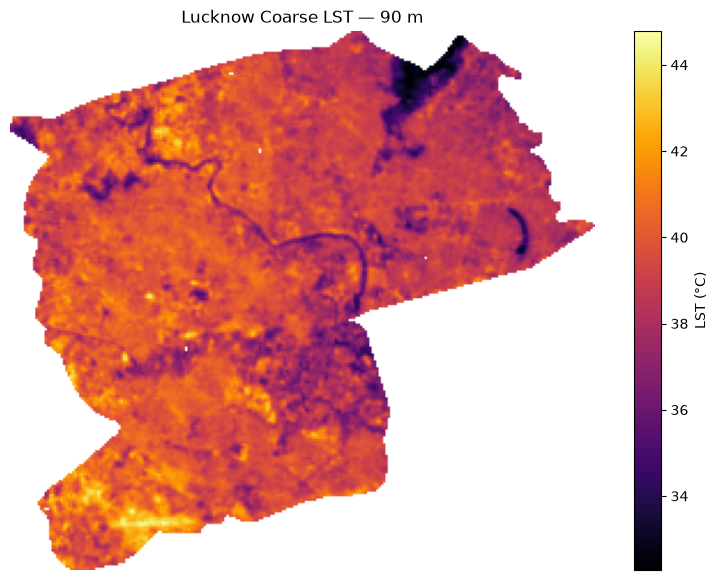

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(
    coarse_lst,
    cmap="inferno"
)

plt.colorbar(label="LST (°C)")
plt.title("Lucknow Coarse LST — 90 m")
plt.axis("off")

plt.show()

### 8. Aggregate NDVI to the 90 m grid

The 30 m NDVI is aggregated to the same 90 m grid used for the coarse LST.

The same 3 × 3 spatial blocks are used so that each coarse NDVI pixel corresponds to the same geographic area as one coarse LST pixel.

NoData values are ignored when calculating the mean.

In [14]:
# Load NDVI

with rasterio.open(raster_paths["NDVI"]) as src:
    ndvi = src.read(1).astype("float32")

    print("NDVI shape:", ndvi.shape)
    print("NDVI resolution:", src.res)

NDVI shape: (703, 762)
NDVI resolution: (30.0, 30.0)


In [15]:
# Trim NDVI to the same complete 3×3 area used for LST

ndvi_trimmed = ndvi[:rows, :cols]

# Convert NoData to NaN

ndvi_for_aggregation = ndvi_trimmed.copy()
ndvi_for_aggregation[ndvi_for_aggregation == -9999] = np.nan

# Create 3×3 blocks

ndvi_blocks = ndvi_for_aggregation.reshape(
    rows // AGG_FACTOR,
    AGG_FACTOR,
    cols // AGG_FACTOR,
    AGG_FACTOR
)

# Calculate the mean NDVI for each coarse pixel

coarse_ndvi = np.nanmean(
    ndvi_blocks,
    axis=(1, 3)
)

# Make completely empty blocks NoData

ndvi_all_nodata = np.all(
    np.isnan(ndvi_blocks),
    axis=(1, 3)
)

coarse_ndvi[ndvi_all_nodata] = np.nan

print("Coarse NDVI shape:", coarse_ndvi.shape)
print("Coarse NDVI valid pixels:", np.sum(~np.isnan(coarse_ndvi)))
print("Coarse NDVI NoData pixels:", np.sum(np.isnan(coarse_ndvi)))

Coarse NDVI shape: (234, 254)
Coarse NDVI valid pixels: 35392
Coarse NDVI NoData pixels: 24044


C:\Users\ANSHIKA\AppData\Local\Temp\ipykernel_22308\935831536.py:21: RuntimeWarning: Mean of empty slice
  coarse_ndvi = np.nanmean(


### 9. Create a common valid-data mask

TsHARP requires paired observations of coarse LST and coarse vegetation information.

Therefore, only pixels where both coarse LST and coarse NDVI are valid will be used for subsequent analysis.

Pixels where either dataset contains NoData are excluded.

In [16]:
# Create a common valid-pixel mask

common_valid_mask = (
    np.isfinite(coarse_lst) &
    np.isfinite(coarse_ndvi)
)

print("Total coarse pixels:", coarse_lst.size)
print("Common valid pixels:", np.sum(common_valid_mask))
print("Excluded pixels:", np.sum(~common_valid_mask))

Total coarse pixels: 59436
Common valid pixels: 35383
Excluded pixels: 24053


In [17]:
# Extract valid 30 m NDVI values

ndvi_valid_mask = np.isfinite(ndvi_trimmed)

valid_ndvi = ndvi_trimmed[ndvi_valid_mask]

print("Valid NDVI pixels:", valid_ndvi.size)
print("Minimum NDVI:", np.min(valid_ndvi))
print("Maximum NDVI:", np.max(valid_ndvi))
print("Mean NDVI:", np.mean(valid_ndvi))
print("Median NDVI:", np.median(valid_ndvi))

Valid NDVI pixels: 314853
Minimum NDVI: 0.027113719
Maximum NDVI: 0.77813345
Mean NDVI: 0.30725604
Median NDVI: 0.28160137


### 10. Calculate fractional vegetation cover (FVC)

TsHARP uses fractional vegetation cover as its sharpening variable.

FVC is derived from NDVI using the published TsHARP formulation:

FVC = 1 - ((NDVI_max - NDVI) / (NDVI_max - NDVI_min))^0.625

where NDVI_min and NDVI_max are the minimum and maximum valid NDVI values in the scene.

FVC values are constrained to the range 0–1.

In [18]:
# NDVI endmembers from the valid scene

ndvi_min = np.min(valid_ndvi)
ndvi_max = np.max(valid_ndvi)

print("NDVI minimum:", ndvi_min)
print("NDVI maximum:", ndvi_max)


# Calculate FVC from the 30 m NDVI

fvc = np.full(ndvi_trimmed.shape, np.nan, dtype="float32")

valid_mask = np.isfinite(ndvi_trimmed)

fvc[valid_mask] = 1 - (
    (ndvi_max - ndvi_trimmed[valid_mask])
    / (ndvi_max - ndvi_min)
) ** 0.625


# Keep FVC within the physical range 0–1

fvc[valid_mask] = np.clip(
    fvc[valid_mask],
    0,
    1
)

print("FVC shape:", fvc.shape)
print("FVC minimum:", np.nanmin(fvc))
print("FVC maximum:", np.nanmax(fvc))
print("FVC mean:", np.nanmean(fvc))

NDVI minimum: 0.027113719
NDVI maximum: 0.77813345
FVC shape: (702, 762)
FVC minimum: 0.0
FVC maximum: 1.0
FVC mean: 0.26018572


### 11. Aggregate FVC to the 90 m grid

The 30 m FVC is aggregated to the same 90 m grid as the coarse LST.

Each 90 m FVC pixel is calculated as the mean of the valid FVC values within its corresponding 3 × 3 block of 30 m pixels.

This produces coarse vegetation-cover information that can be paired with the 90 m LST for the TsHARP regression.

In [19]:
# Create 3 × 3 FVC blocks

fvc_blocks = fvc.reshape(
    rows // AGG_FACTOR,
    AGG_FACTOR,
    cols // AGG_FACTOR,
    AGG_FACTOR
)

# Calculate mean FVC while ignoring NaN

coarse_fvc = np.nanmean(
    fvc_blocks,
    axis=(1, 3)
)

# Identify completely invalid blocks

fvc_all_nodata = np.all(
    np.isnan(fvc_blocks),
    axis=(1, 3)
)

coarse_fvc[fvc_all_nodata] = np.nan

print("Coarse FVC shape:", coarse_fvc.shape)
print("Coarse FVC valid pixels:", np.sum(~np.isnan(coarse_fvc)))
print("Coarse FVC NoData pixels:", np.sum(np.isnan(coarse_fvc)))

Coarse FVC shape: (234, 254)
Coarse FVC valid pixels: 35392
Coarse FVC NoData pixels: 24044


C:\Users\ANSHIKA\AppData\Local\Temp\ipykernel_22308\2768941154.py:12: RuntimeWarning: Mean of empty slice
  coarse_fvc = np.nanmean(


In [20]:
print("Minimum coarse FVC:", np.nanmin(coarse_fvc))
print("Maximum coarse FVC:", np.nanmax(coarse_fvc))
print("Mean coarse FVC:", np.nanmean(coarse_fvc))
print("Median coarse FVC:", np.nanmedian(coarse_fvc))

Minimum coarse FVC: 0.06414327
Maximum coarse FVC: 0.84949887
Mean coarse FVC: 0.26100278
Median coarse FVC: 0.23312835


### 12. Prepare paired LST–FVC observations

TsHARP establishes a relationship between coarse-resolution LST and fractional vegetation cover.

Only pixels where both coarse LST and coarse FVC are valid are used.

Each valid pixel therefore contributes one paired observation:

    coarse FVC → coarse LST

In [21]:
# Create a common valid mask for coarse LST and coarse FVC

tsharp_valid_mask = (
    np.isfinite(coarse_lst) &
    np.isfinite(coarse_fvc)
)

# Extract paired observations

lst_tsharp = coarse_lst[tsharp_valid_mask]
fvc_tsharp = coarse_fvc[tsharp_valid_mask]

print("Number of paired observations:", len(lst_tsharp))
print("LST range:", lst_tsharp.min(), "to", lst_tsharp.max())
print("FVC range:", fvc_tsharp.min(), "to", fvc_tsharp.max())

Number of paired observations: 35383
LST range: 32.28329 to 44.784115
FVC range: 0.06414327 to 0.84949887


### 13. Explore the coarse FVC–LST relationship

TsHARP assumes that coarse-resolution LST has a systematic relationship with fractional vegetation cover.

Before fitting the regression, we visualize the relationship between coarse FVC and coarse LST.

This helps us determine whether an approximately inverse relationship is present in the Lucknow scene.

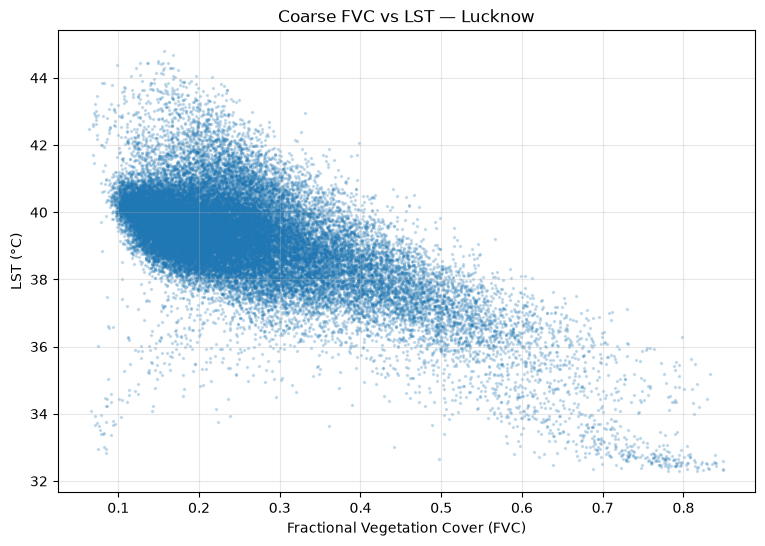

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    fvc_tsharp,
    lst_tsharp,
    s=2,
    alpha=0.2
)

plt.xlabel("Fractional Vegetation Cover (FVC)")
plt.ylabel("LST (°C)")
plt.title("Coarse FVC vs LST — Lucknow")
plt.grid(alpha=0.3)

plt.show()

### 14. Quantify the coarse FVC–LST relationship

The scatter plot shows an inverse relationship between FVC and LST.

We now quantify this relationship using Pearson correlation and a simple linear regression.

These statistics provide an initial assessment of how strongly vegetation cover explains coarse-scale LST variation in the study area.

In [23]:
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Pearson correlation
correlation, p_value = pearsonr(
    fvc_tsharp,
    lst_tsharp
)

# Linear regression
X = fvc_tsharp.reshape(-1, 1)
y = lst_tsharp

regression = LinearRegression()
regression.fit(X, y)

lst_pred = regression.predict(X)

# Regression statistics
slope = regression.coef_[0]
intercept = regression.intercept_
r2 = r2_score(y, lst_pred)

print("Pearson correlation:", correlation)
print("p-value:", p_value)
print("Slope:", slope)
print("Intercept:", intercept)
print("R²:", r2)

Pearson correlation: -0.6756073
p-value: 0.0
Slope: -8.336348
Intercept: 41.347336
R²: 0.45644503831863403


### 15. Generate the initial 30 m TsHARP LST

The regression coefficients obtained from the 90 m coarse-resolution relationship are applied to the 30 m FVC.

This produces an initial 30 m LST estimate.

This is not yet the final TsHARP result because the coarse-scale residual correction still needs to be applied.

In [24]:
# Create the initial 30 m TsHARP LST

tsharp_lst_30m_initial = np.full(
    fvc.shape,
    np.nan,
    dtype="float32"
)

fvc_valid = np.isfinite(fvc)

tsharp_lst_30m_initial[fvc_valid] = (
    intercept +
    slope * fvc[fvc_valid]
)

print("Initial TsHARP LST shape:", tsharp_lst_30m_initial.shape)
print(
    "Initial LST range:",
    np.nanmin(tsharp_lst_30m_initial),
    "to",
    np.nanmax(tsharp_lst_30m_initial)
)

Initial TsHARP LST shape: (702, 762)
Initial LST range: 33.010986 to 41.347336


### 16. Calculate the TsHARP residual

The initial fine-resolution LST is aggregated back to the coarse 90 m grid.

The difference between the original coarse LST and this reconstructed coarse LST represents the coarse-scale residual error.

This residual will later be transferred to the 30 m grid and added to the initial TsHARP prediction.

In [25]:
# Prepare the initial 30 m TsHARP LST for aggregation

initial_lst_blocks = tsharp_lst_30m_initial.reshape(
    rows // AGG_FACTOR,
    AGG_FACTOR,
    cols // AGG_FACTOR,
    AGG_FACTOR
)

# Aggregate the predicted 30 m LST to 90 m

initial_lst_coarse = np.nanmean(
    initial_lst_blocks,
    axis=(1, 3)
)

# Identify completely invalid blocks

initial_lst_all_nodata = np.all(
    np.isnan(initial_lst_blocks),
    axis=(1, 3)
)

initial_lst_coarse[initial_lst_all_nodata] = np.nan

print("Reconstructed coarse LST shape:", initial_lst_coarse.shape)
print(
    "Reconstructed coarse LST range:",
    np.nanmin(initial_lst_coarse),
    "to",
    np.nanmax(initial_lst_coarse)
)

Reconstructed coarse LST shape: (234, 254)
Reconstructed coarse LST range: 34.265617 to 40.812614


C:\Users\ANSHIKA\AppData\Local\Temp\ipykernel_22308\1574311037.py:12: RuntimeWarning: Mean of empty slice
  initial_lst_coarse = np.nanmean(


In [26]:
# Calculate coarse residual

residual_coarse = coarse_lst - initial_lst_coarse

# Only keep pixels where both are valid

residual_valid_mask = (
    np.isfinite(coarse_lst) &
    np.isfinite(initial_lst_coarse)
)

residual_coarse[~residual_valid_mask] = np.nan

print("Residual shape:", residual_coarse.shape)
print("Residual minimum:", np.nanmin(residual_coarse))
print("Residual maximum:", np.nanmax(residual_coarse))
print("Residual mean:", np.nanmean(residual_coarse))
print("Residual median:", np.nanmedian(residual_coarse))

Residual shape: (234, 254)
Residual minimum: -7.803314
Residual maximum: 4.7459526
Residual mean: 1.1039906e-06
Residual median: -0.06174469


### 17. Transfer the coarse residual to the 30 m grid

The 90 m residual represents the coarse-scale temperature error that is not explained by the FVC-based regression.

The residual is mapped back to the 30 m grid by assigning each 90 m residual to its corresponding 3 × 3 block of 30 m pixels.

The final TsHARP LST is obtained by adding this residual correction to the initial 30 m LST estimate.

In [27]:
# Expand each 90 m residual into its corresponding 3 × 3 block

residual_30m = np.repeat(
    np.repeat(
        residual_coarse,
        AGG_FACTOR,
        axis=0
    ),
    AGG_FACTOR,
    axis=1
)

print("Residual 90 m shape :", residual_coarse.shape)
print("Residual 30 m shape :", residual_30m.shape)

Residual 90 m shape : (234, 254)
Residual 30 m shape : (702, 762)


In [28]:
# Create final TsHARP LST

tsharp_lst_30m = (
    tsharp_lst_30m_initial +
    residual_30m
)

# Keep only pixels where the initial prediction and residual are valid

final_valid_mask = (
    np.isfinite(tsharp_lst_30m_initial) &
    np.isfinite(residual_30m)
)

tsharp_lst_30m[~final_valid_mask] = np.nan

print("Final TsHARP LST shape:", tsharp_lst_30m.shape)
print(
    "Final TsHARP LST range:",
    np.nanmin(tsharp_lst_30m),
    "to",
    np.nanmax(tsharp_lst_30m)
)
print(
    "Final TsHARP LST mean:",
    np.nanmean(tsharp_lst_30m)
)

Final TsHARP LST shape: (702, 762)
Final TsHARP LST range: 30.97588 to 45.25235
Final TsHARP LST mean: 39.17682


### 18. Check coarse-scale consistency of the final TsHARP LST

The final 30 m TsHARP LST is aggregated back to the 90 m grid.

It is then compared with the original 90 m coarse LST used in the residual calculation.

This is an internal consistency check of the TsHARP implementation, not an independent accuracy assessment.

In [29]:
# Aggregate final 30 m TsHARP LST back to 90 m

final_lst_blocks = tsharp_lst_30m.reshape(
    rows // AGG_FACTOR,
    AGG_FACTOR,
    cols // AGG_FACTOR,
    AGG_FACTOR
)

final_lst_coarse = np.nanmean(
    final_lst_blocks,
    axis=(1, 3)
)

# Identify completely invalid blocks

final_all_nodata = np.all(
    np.isnan(final_lst_blocks),
    axis=(1, 3)
)

final_lst_coarse[final_all_nodata] = np.nan

print("Final coarse LST shape:", final_lst_coarse.shape)

Final coarse LST shape: (234, 254)


C:\Users\ANSHIKA\AppData\Local\Temp\ipykernel_22308\1454814097.py:10: RuntimeWarning: Mean of empty slice
  final_lst_coarse = np.nanmean(


In [30]:
# Compare final coarse LST with original coarse LST

comparison_mask = (
    np.isfinite(coarse_lst) &
    np.isfinite(final_lst_coarse)
)

coarse_difference = (
    final_lst_coarse[comparison_mask]
    - coarse_lst[comparison_mask]
)

print("Number of compared pixels:", comparison_mask.sum())
print("Mean difference:", np.mean(coarse_difference))
print("Maximum absolute difference:", np.max(np.abs(coarse_difference)))
print("RMSE:", np.sqrt(np.mean(coarse_difference ** 2)))

Number of compared pixels: 35383
Mean difference: 3.0187245e-08
Maximum absolute difference: 7.6293945e-06
RMSE: 2.5889872e-06


### 19. Save the final 30 m TsHARP LST

The final TsHARP LST combines the initial FVC-based prediction with the coarse residual correction.

The result is saved as a 30 m GeoTIFF using the spatial reference of the original Landsat LST grid.

The final raster covers the complete 3 × 3 aggregation area used throughout the experiment.

In [31]:
# Output path
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "lucknow"/ "downscaled"
tsharp_lst_path = PROCESSED_DIR / "tsharp_lst_30m_lucknow.tif"


# Create profile for the final TsHARP LST

tsharp_profile = lst_profile.copy()

tsharp_profile.update({
    "driver": "GTiff",
    "height": tsharp_lst_30m.shape[0],
    "width": tsharp_lst_30m.shape[1],
    "count": 1,
    "dtype": "float32",
    "crs": "EPSG:32644",
    "transform": lst_transform,
    "nodata": -9999.0
})


# Replace NaN with NoData

tsharp_to_save = np.where(
    np.isnan(tsharp_lst_30m),
    -9999.0,
    tsharp_lst_30m
).astype("float32")


# Save GeoTIFF

with rasterio.open(
    tsharp_lst_path,
    "w",
    **tsharp_profile
) as dst:
    dst.write(tsharp_to_save, 1)

print("Saved:", tsharp_lst_path)

Saved: d:\Projects\GeoAI-LST-Downscaling\data\processed\lucknow\downscaled\tsharp_lst_30m_lucknow.tif


In [32]:
with rasterio.open(tsharp_lst_path) as src:

    data = src.read(1)

    valid = data != src.nodata

    print("Shape      :", data.shape)
    print("CRS        :", src.crs)
    print("Resolution :", src.res)
    print("NoData     :", src.nodata)
    print("Minimum    :", data[valid].min())
    print("Maximum    :", data[valid].max())
    print("Mean       :", data[valid].mean())

Shape      : (702, 762)
CRS        : EPSG:32644
Resolution : (30.0, 30.0)
NoData     : -9999.0
Minimum    : 30.97588
Maximum    : 45.25235
Mean       : 39.17682


### 20. Visualize the final TsHARP LST

The final 30 m TsHARP LST is visualized to inspect its spatial distribution and compare it with the original Landsat LST.

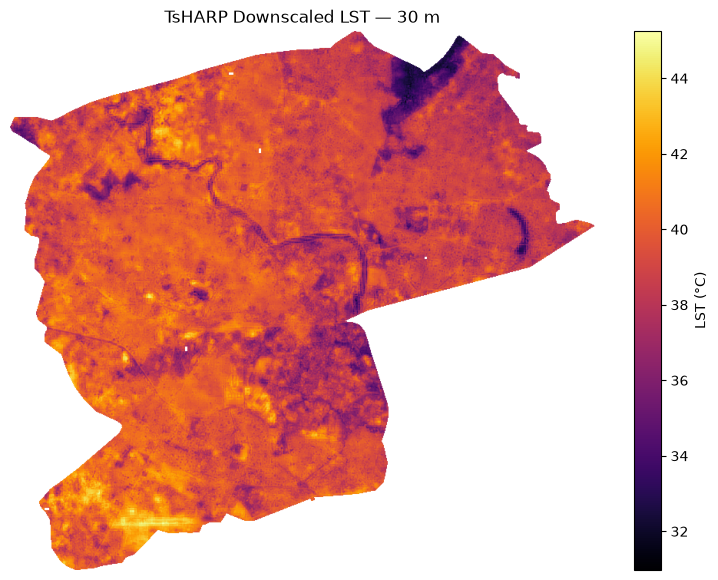

In [33]:
plt.figure(figsize=(10, 7))

plt.imshow(
    tsharp_lst_30m,
    cmap="inferno"
)

plt.colorbar(label="LST (°C)")
plt.title("TsHARP Downscaled LST — 30 m")
plt.axis("off")

plt.show()

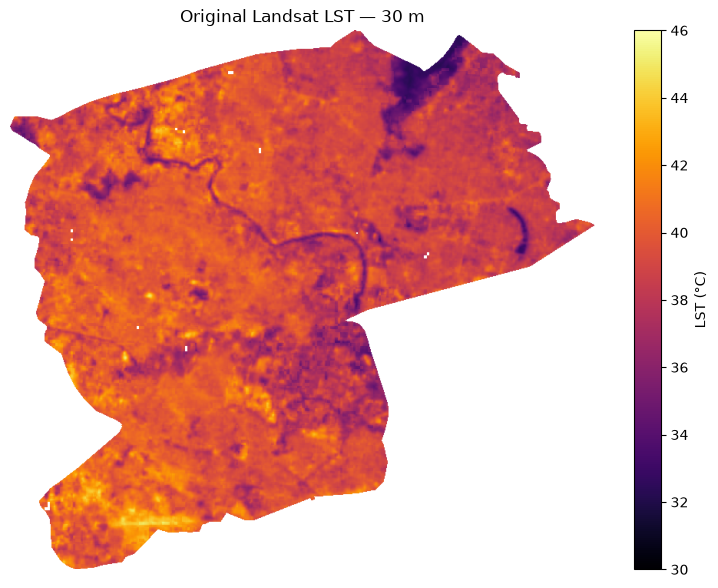

In [34]:
# Create a plotting copy of the original LST

lst_plot = lst_trimmed.astype("float32").copy()

# Convert NoData to NaN for plotting
lst_plot[lst_plot == -9999] = np.nan


plt.figure(figsize=(10, 7))

plt.imshow(
    lst_plot,
    cmap="inferno",
    vmin=30,
    vmax=46
)

plt.colorbar(label="LST (°C)")
plt.title("Original Landsat LST — 30 m")
plt.axis("off")

plt.show()

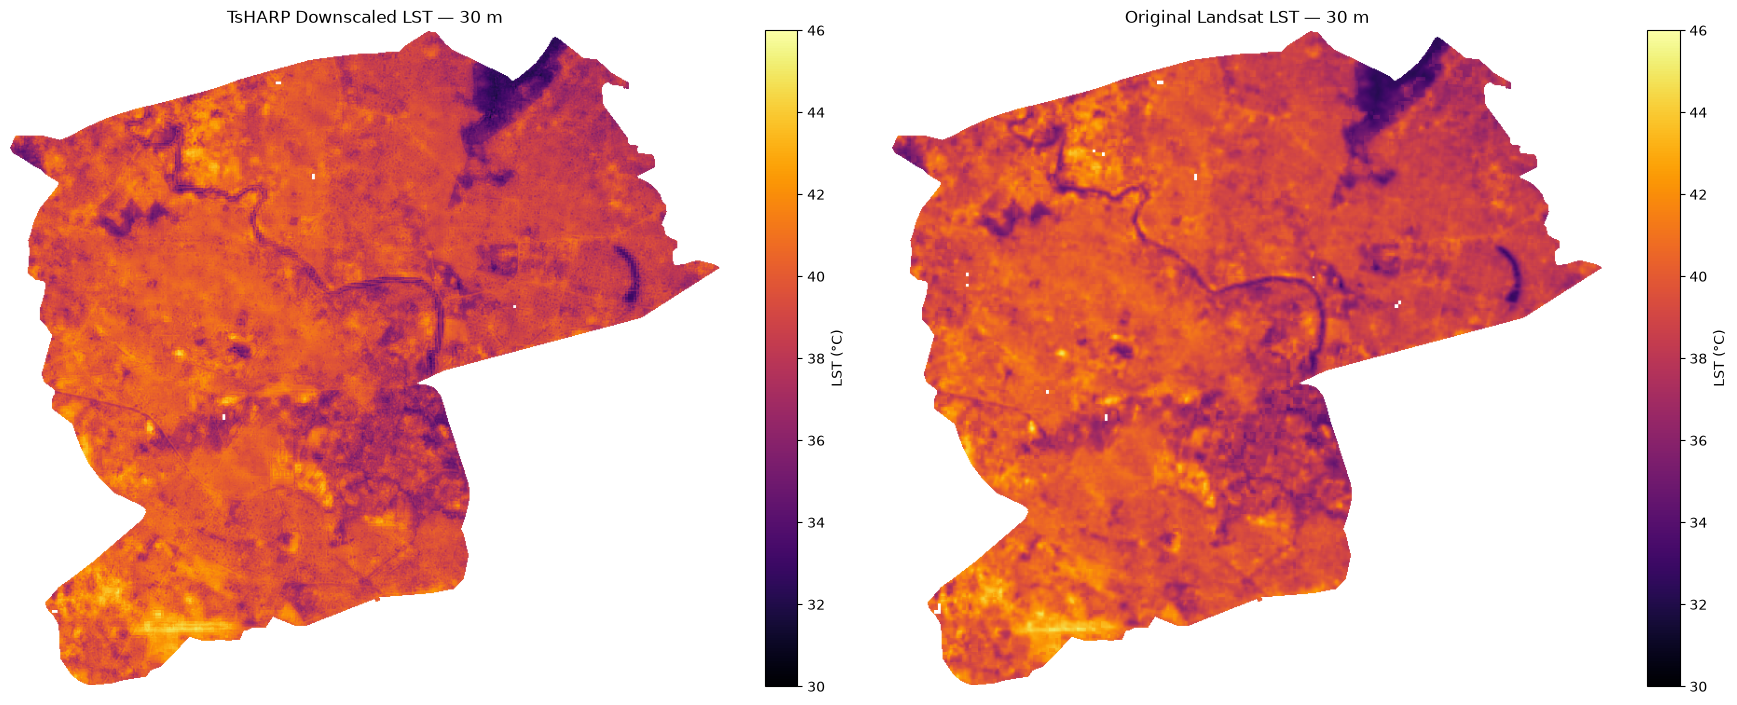

In [35]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

im0 = axes[0].imshow(
    tsharp_lst_30m,
    cmap="inferno",
    vmin=30,
    vmax=46
)
axes[0].set_title("TsHARP Downscaled LST — 30 m")
axes[0].axis("off")
fig.colorbar(im0, ax=axes[0], label="LST (°C)")

im1 = axes[1].imshow(
    lst_plot,
    cmap="inferno",
    vmin=30,
    vmax=46
)
axes[1].set_title("Original Landsat LST — 30 m")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], label="LST (°C)")

plt.tight_layout()
plt.show()

### 21. Compare TsHARP LST with the original 30 m Landsat LST

The final TsHARP 30 m LST is compared with the original 30 m Landsat LST.

The comparison provides a quantitative assessment of how closely the TsHARP estimate reproduces the original fine-resolution thermal pattern.

Because the 90 m coarse LST used by TsHARP was derived from the same original 30 m LST, this comparison represents a pseudo-validation/reconstruction experiment rather than an independent validation.

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

# Create valid comparison mask

original_valid = np.isfinite(lst_trimmed)
tsharp_valid = np.isfinite(tsharp_lst_30m)

comparison_mask_30m = (
    original_valid &
    tsharp_valid
)

# Extract paired values

original_30m = lst_trimmed[comparison_mask_30m]
tsharp_30m = tsharp_lst_30m[comparison_mask_30m]

print("Number of compared pixels:", len(original_30m))


# Metrics

mae = mean_absolute_error(
    original_30m,
    tsharp_30m
)

rmse = np.sqrt(
    mean_squared_error(
        original_30m,
        tsharp_30m
    )
)

r2 = r2_score(
    original_30m,
    tsharp_30m
)

correlation, p_value = pearsonr(
    original_30m,
    tsharp_30m
)

bias = np.mean(
    tsharp_30m - original_30m
)


print("MAE :", mae, "°C")
print("RMSE:", rmse, "°C")
print("R²  :", r2)
print("Pearson r:", correlation)
print("Mean bias:", bias, "°C")

Number of compared pixels: 314648
MAE : 0.31992825865745544 °C
RMSE: 0.43265018380356385 °C
R²  : 0.9177131056785583
Pearson r: 0.95989877
Mean bias: 2.0649446e-05 °C


In [37]:
# Correct validation mask

original_valid = (
    np.isfinite(lst_trimmed) &
    (lst_trimmed != -9999)
)

tsharp_valid = np.isfinite(tsharp_lst_30m)

comparison_mask_30m = (
    original_valid &
    tsharp_valid
)

# Extract paired values

original_30m = lst_trimmed[comparison_mask_30m]
tsharp_30m = tsharp_lst_30m[comparison_mask_30m]

print("Number of compared pixels:", len(original_30m))


# Calculate metrics

mae = mean_absolute_error(
    original_30m,
    tsharp_30m
)

rmse = np.sqrt(
    mean_squared_error(
        original_30m,
        tsharp_30m
    )
)

r2 = r2_score(
    original_30m,
    tsharp_30m
)

correlation, p_value = pearsonr(
    original_30m,
    tsharp_30m
)

bias = np.mean(
    tsharp_30m - original_30m
)


print("MAE :", mae, "°C")
print("RMSE:", rmse, "°C")
print("R²  :", r2)
print("Pearson r:", correlation)
print("Mean bias:", bias, "°C")

Number of compared pixels: 314648
MAE : 0.31992825865745544 °C
RMSE: 0.43265018380356385 °C
R²  : 0.9177131056785583
Pearson r: 0.95989877
Mean bias: 2.0649446e-05 °C


### 22. Spatial error analysis

The absolute difference between the TsHARP LST and the original 30 m Landsat LST is mapped to identify areas where the downscaled estimate differs most strongly from the original LST.

This is a pseudo-validation diagnostic because the original LST was also used to construct the coarse input.

In [38]:
# Calculate absolute error

absolute_error = np.full(
    lst_trimmed.shape,
    np.nan,
    dtype="float32"
)

absolute_error[comparison_mask_30m] = np.abs(
    tsharp_lst_30m[comparison_mask_30m]
    - lst_trimmed[comparison_mask_30m]
)

print("Minimum absolute error:", np.nanmin(absolute_error))
print("Maximum absolute error:", np.nanmax(absolute_error))
print("Mean absolute error:", np.nanmean(absolute_error))
print("Median absolute error:", np.nanmedian(absolute_error))

Minimum absolute error: 0.0
Maximum absolute error: 3.468502
Mean absolute error: 0.3199283
Median absolute error: 0.24052429


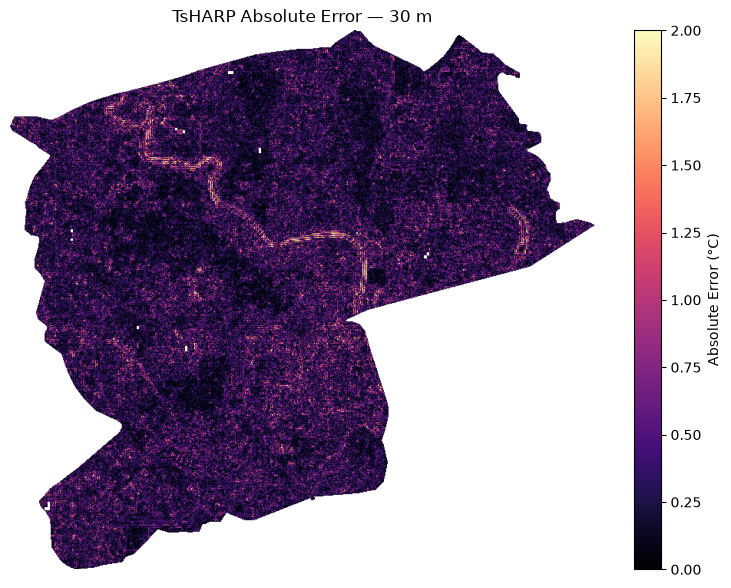

In [39]:
plt.figure(figsize=(10, 7))

plt.imshow(
    absolute_error,
    cmap="magma",
    vmin=0,
    vmax=2
)

plt.colorbar(label="Absolute Error (°C)")
plt.title("TsHARP Absolute Error — 30 m")
plt.axis("off")

plt.show()

### 23. Save the important png and GeoTiff files

The 30 m fractional vegetation cover derived from NDVI is saved for reuse in subsequent analysis and downscaling experiments.

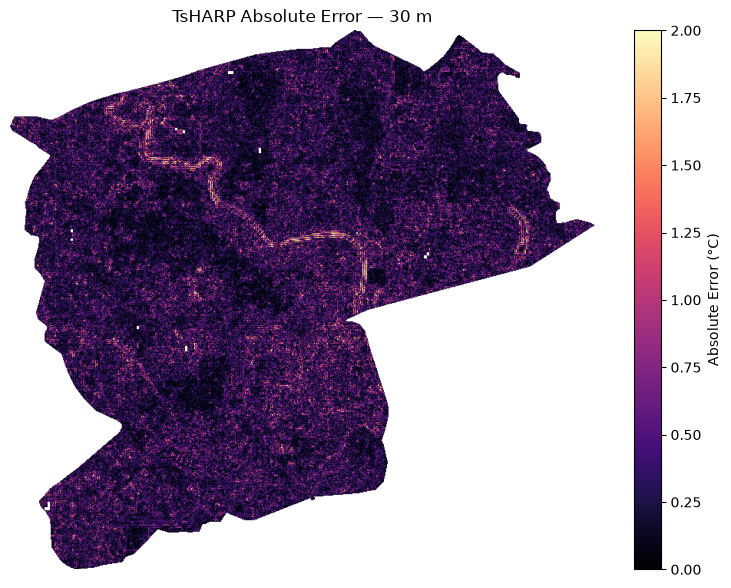

Saved: d:\Projects\GeoAI-LST-Downscaling\figures\lucknow\notebook_3\tsharp_absolute_error_30m.png


In [40]:
FIGURES_DIR = PROJECT_ROOT / "figures"/ "lucknow"/ "notebook_3"
error_png_path = FIGURES_DIR / "tsharp_absolute_error_30m.png"

plt.figure(figsize=(10, 7))

plt.imshow(
    absolute_error,
    cmap="magma",
    vmin=0,
    vmax=2
)

plt.colorbar(label="Absolute Error (°C)")
plt.title("TsHARP Absolute Error — 30 m")
plt.axis("off")

plt.savefig(
    error_png_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", error_png_path)

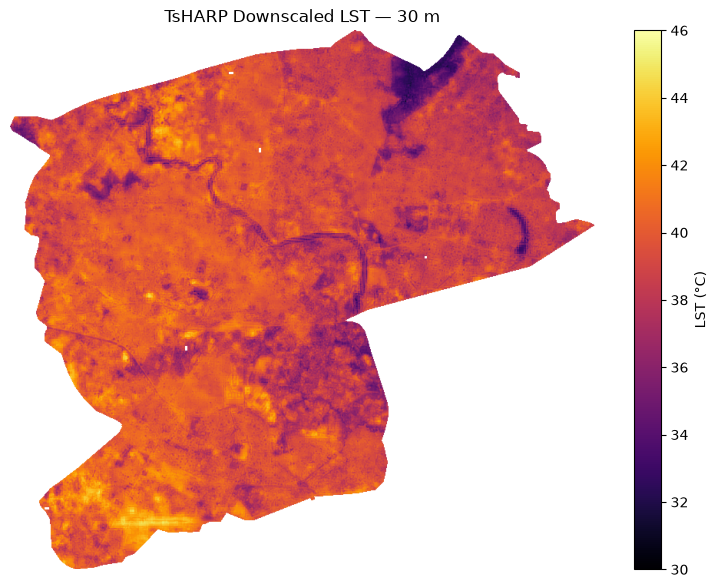

Saved: d:\Projects\GeoAI-LST-Downscaling\figures\lucknow\notebook_3\tsharp_lst_30m.png


In [41]:
tsharp_png_path = FIGURES_DIR / "tsharp_lst_30m.png"

plt.figure(figsize=(10, 7))

plt.imshow(
    tsharp_lst_30m,
    cmap="inferno",
    vmin=30,
    vmax=46
)

plt.colorbar(label="LST (°C)")
plt.title("TsHARP Downscaled LST — 30 m")
plt.axis("off")

plt.savefig(
    tsharp_png_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", tsharp_png_path)

In [42]:
# Create output directory
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

FVC_DIR = PROCESSED_DIR / "lucknow"/ "fine" / "indices"
FVC_DIR.mkdir(parents=True, exist_ok=True)

fvc_path = FVC_DIR / "fvc_30m_lucknow.tif"


# Create FVC GeoTIFF profile

fvc_profile = lst_profile.copy()

fvc_profile.update({
    "driver": "GTiff",
    "height": fvc.shape[0],
    "width": fvc.shape[1],
    "count": 1,
    "dtype": "float32",
    "crs": "EPSG:32644",
    "transform": lst_transform,
    "nodata": -9999.0
})


# Replace NaN with NoData

fvc_to_save = np.where(
    np.isnan(fvc),
    -9999.0,
    fvc
).astype("float32")


# Save

with rasterio.open(
    fvc_path,
    "w",
    **fvc_profile
) as dst:
    dst.write(fvc_to_save, 1)

print("Saved:", fvc_path)

Saved: d:\Projects\GeoAI-LST-Downscaling\data\processed\lucknow\fine\indices\fvc_30m_lucknow.tif


# Results and Observations

## 1. Coarse LST and FVC Relationship

The 30 m Landsat LST was aggregated to a 90 m spatial resolution using 3 × 3 pixel blocks. The corresponding NDVI was converted to fractional vegetation cover (FVC), which was also aggregated to the 90 m grid.

A total of **35,383 valid paired observations** were available for the TsHARP analysis.

The coarse-resolution LST–FVC relationship showed a clear inverse relationship:

- Pearson correlation: **−0.676**
- R²: **0.456**
- Regression slope: **−8.336 °C per unit FVC**
- Regression intercept: **41.347 °C**

This indicates that vegetation cover explains a substantial portion of the spatial variation in LST, with higher vegetation cover generally associated with lower surface temperature. However, the R² of 0.456 also indicates that FVC alone does not explain all of the observed LST variation.

This is particularly relevant for the urban study area, where temperature is also influenced by built-up surfaces, water, soil and other land-surface characteristics.

---

## 2. TsHARP Downscaling

The coarse LST–FVC relationship was used to generate an initial 30 m LST estimate. A coarse-scale residual correction was subsequently calculated and transferred to the 30 m grid to obtain the final TsHARP LST.

The final TsHARP LST had the following characteristics:

- Spatial resolution: **30 m**
- Shape: **702 × 762**
- CRS: **EPSG:32644**
- Minimum LST: **30.98 °C**
- Maximum LST: **45.25 °C**
- Mean LST: **39.18 °C**

The final TsHARP result preserved the broad spatial temperature patterns observed in the original Landsat LST while providing a vegetation-based downscaled estimate.

---

## 3. Coarse-Scale Consistency Check

The final 30 m TsHARP LST was aggregated back to the 90 m resolution and compared with the original coarse LST.

The reconstruction produced:

- Mean difference: **3.02 × 10⁻⁸ °C**
- Maximum absolute difference: **7.63 × 10⁻⁶ °C**
- RMSE: **2.59 × 10⁻⁶ °C**

These differences are effectively zero and are attributable to floating-point numerical precision.

This confirms that the residual-correction implementation is internally consistent.

**This should not be interpreted as an independent accuracy assessment**, because the residual was explicitly constructed from the original coarse LST.

---

## 4. Pseudo-Validation Against Original 30 m LST

The final TsHARP LST was compared with the original 30 m Landsat LST over **314,648 valid pixels**.

The resulting metrics were:

- MAE: **0.320 °C**
- RMSE: **0.433 °C**
- R²: **0.918**
- Pearson correlation: **0.960**
- Mean bias: **0.00002 °C**
- Median absolute error: **0.241 °C**
- Maximum absolute error: **3.469 °C**

The results indicate a strong correspondence between the TsHARP estimate and the original 30 m LST in this controlled experiment.

However, this comparison is a **pseudo-validation/reconstruction experiment rather than independent validation**. The original 30 m LST was first aggregated to create the 90 m coarse input used by TsHARP. Therefore, these metrics should not be interpreted as independent real-world accuracy.

---

## 5. Error Analysis

The absolute error between the TsHARP estimate and the original 30 m LST had:

- Minimum absolute error: **0.000 °C**
- Maximum absolute error: **3.469 °C**
- Mean absolute error: **0.320 °C**
- Median absolute error: **0.241 °C**

Most pixels therefore had relatively small differences, while a smaller number of locations showed larger errors.

The spatial error map provides an additional diagnostic for identifying areas where the vegetation-based TsHARP approach has greater difficulty reproducing the original LST pattern.

---

## 6. Key Observations

1. A clear inverse relationship was observed between FVC and LST at the coarse resolution.

2. FVC alone explained approximately **45.6%** of the coarse LST variation, indicating that vegetation is an important but incomplete predictor of surface temperature.

3. The TsHARP residual correction successfully maintained coarse-scale consistency with the original 90 m LST.

4. The final TsHARP product reproduced the broad spatial structure of the original 30 m LST with relatively small differences in this pseudo-validation experiment.

5. The remaining errors indicate that vegetation information alone cannot completely represent the spatial variability of urban LST.

6. These limitations motivate the next stage of the project, where additional predictors such as **NDVI, NDBI, MNDWI, Green, SWIR1 and SWIR2** can be investigated for LST downscaling using machine-learning approaches.

---

## 7. Important Limitation

The TsHARP assessment performed in this notebook is based on a single Landsat scene and uses the original 30 m LST to construct the coarse-resolution input.

Therefore, the results demonstrate the behaviour and implementation of the TsHARP method under a controlled spatial-degradation experiment rather than proving its generalization to unseen observations.

Further evaluation using independent observations, additional dates, or an independent reference dataset would be required for a stronger assessment of real-world performance.